# E02 — A single-family house: foundation earth electrode in concrete

This case study models the earth of a detached single-family house: a
foundation earth electrode in the concrete of the strip foundation,
optionally with a driven rod or a ring earth electrode outside the
foundation. It is written for the grounding engineer who wants to know
what such an earth achieves, how much the concrete and the soil change
it, and which of groundfield's engines to trust for which answer.

**The questions**

1. What is the earthing resistance of the house, and how much do the
   concrete and the soil model change it?
2. What do people around the house experience when its earth rises in
   potential: the potential profile, the touch voltage at the façade and
   the step voltage?
3. What does a driven rod or a ring earth electrode outside the
   foundation add?
4. What do the engines `image` / `image_2layer`, `mom` and `fem` give for
   this house, and why do they differ?

**Prerequisites:** the tutorials
[T01](../tutorials/T01_first_grounding_impedance.ipynb),
[T02](../tutorials/T02_layered_soil.ipynb),
[T08](../tutorials/T08_touch_and_step_assessment.ipynb) and
[T09](../tutorials/T09_choosing_an_engine_and_convergence.ipynb), and the
page [Concrete-encased electrodes](../explanation/concrete-shells.md).
Runtime: about half a minute. An optional three-dimensional `fem` run
near the end takes one to three minutes and up to 3.5 GB of memory more;
it is switched off.

## The house and its earth

The house has a footprint of 10 m × 10 m and stands on a strip
foundation whose base lies 0.8 m below ground. The foundation earth
electrode (*Fundamenterder*, DIN 18014) is a round steel bar of 10 mm
diameter on the axis of the strip, with 5 cm of concrete all round. It
runs as a closed loop under the outer walls. The model house of
groundfield's generators (the `residential` entry of
`default_building_catalog()`) adds one cross-brace each way, for example
under inner load-bearing walls: six straight bars of 10 m, 60 m of steel
in concrete. DIN 18014 itself asks for cross-braces only where a mesh
would exceed 20 m × 20 m; the next section shows what they change.

The foundation earth electrode is the earth of the house: the main
earthing terminal, the protective bonding of the water and gas pipes and,
in a TN-C-S system, the earthing of the PEN conductor at the service
entrance all connect to it. Three variants, every part bonded to the
foundation:

- **A — the foundation earth electrode** alone;
- **B — A plus a driven rod**, 6 m long, head 0.5 m deep, 1 m in front of
  the middle of the street-side wall (the service entrance; the black
  square in the plan below);
- **C — A plus a ring earth electrode**, a bare 10 mm steel loop in the
  soil 1 m outside the foundation (12 m × 12 m, 0.8 m deep). Where the
  foundation has no contact with the soil (perimeter insulation,
  waterproof concrete, a bitumen seal), DIN 18014 asks for an earth
  electrode in the soil instead, typically such a ring, and the steel in
  the foundation then serves only the equipotential bonding.

Three soils:

- **S1**, homogeneous 100 Ω·m, the reference;
- **S2**, 300 Ω·m over 30 Ω·m with the interface 2 m deep: dry sand over
  a water-bearing layer (reflection factor $K < 0$);
- **S3**, 50 Ω·m over 500 Ω·m with the interface 2 m deep: loam over dry
  gravel ($K > 0$).

## Modelling choices

- **A quasi-static field at 50 Hz.** The earth of the house spans about
  12 m and contains no long conductor. Below 1 kHz the soil behaves as a
  resistive conductor, so the earth is a resistance $R_E$. The bonds
  between the bars are ideal (the generators' default), and the
  impedance has no imaginary part.
- **Two-layer soil**, as a sounding (Wenner, Schlumberger) would give
  it, solved with the Tagg/Sunde image series of `image_2layer`, which
  the default engine selects by itself.
- **The engines.** The default `image` engine (one uniform current per
  straight wire, exact line-source kernel) gives the resistances. `mom`
  (one current per segment) gives the field next to the house, where the
  image engine warns that its uniform current is only impedance-grade.
  `fem` (solid conductors in a meshed soil) is the independent reference.
  The segments are 0.5 m long: more than five outer radii, as the
  thin-wire check asks.

**Concrete as a cylindrical shell** (ADR-0012, after Sunde). A concrete
cover of thickness $t$ and resistivity $\rho_c$ around a bar of radius
$r_a$ adds, per metre of bar, the radial resistance

$$
C = \frac{\rho_c}{2\pi}\,\ln\frac{r_a + t}{r_a}
\qquad\text{in }\Omega\cdot\mathrm{m},
$$

and the soil sees a bare wire of the outer radius $r_b = r_a + t$ (here
55 mm). If the current leaves the $L$ metres of encased bar evenly, the
shell adds the series resistance $C/L$. Given `concrete_rho_ohm_m`, the
generators put $r_b$ and $C$ on every bar of the foundation, the
cross-braces included. ADR-0012 lists fresh or wet concrete at
30 … 80 Ω·m, earth-moist concrete at 80 … 200 Ω·m, concrete in cycling
humidity at 200 … 2 000 Ω·m and dry concrete at 5 000 Ω·m and more. The
base case takes 150 Ω·m (earth-moist); a sweep covers the rest.

In [1]:
import math
import time
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

import groundfield as gf
from groundfield.generators import (
    FoundationElectrodeSpec,
    GroundingSystemSpec,
    RodElectrodeSpec,
)
from groundfield.references import ieee80

print("groundfield", gf.__version__)

R_A, COVER, DEPTH, SIDE = 0.005, 0.05, 0.8, 10.0  # m: bar radius, cover, depth, side
RHO_C = 150.0  # Ohm m: earth-moist concrete, the base case
SOILS = {
    "S1": gf.HomogeneousSoil(rho=100.0),
    "S2": gf.TwoLayerSoil(rho_1=300.0, rho_2=30.0, h_1=2.0),
    "S3": gf.TwoLayerSoil(rho_1=50.0, rho_2=500.0, h_1=2.0),
}
ROD = RodElectrodeSpec(length_m=6.0, depth_m=0.5, offset_xy_m=(0.0, -6.0))
RING = FoundationElectrodeSpec(style="ring", size_m=SIDE + 2.0, depth_m=DEPTH)  # bare
VARIANTS = {"A": (), "B": (ROD,), "C": (RING,)}
FOUNDATION = "house_foundation_0"  # the generators' name of the first bar


def house(soil, rho_c=RHO_C, extras=(), style="mesh"):
    # The house earth (foundation plus extras, bonded), fed with 1 A.
    # rho_c=None: the bars lie bare in the soil.
    world = gf.create_world(soil=soil, name="E02 house")
    foundation = FoundationElectrodeSpec(
        style=style,
        size_m=SIDE,
        depth_m=DEPTH,
        wire_radius_m=R_A,
        concrete_rho_ohm_m=rho_c,
        concrete_thickness_m=COVER,
    )
    spec = GroundingSystemSpec(electrodes=[foundation, *extras])
    anchor = spec.build_at(world, (0.0, 0.0), "house", np.random.default_rng(0))
    gf.create_source(world, attached_to=anchor, magnitude=1.0)
    return world


IMAGE = gf.create_engine(segment_length=0.5)  # image_2layer in two layers
MOM = gf.create_engine(backend="mom", segment_length=0.5)


def r_e(world, engine=IMAGE):
    # Earthing resistance in Ohm: the input impedance at 50 Hz.
    return engine.solve(world).input_impedance()[0].real

groundfield 2026.11.0


house_foundation_0     polyline 10.0 m, r_b = 55 mm, C = 57.25 Ohm m
house_foundation_0_w1  polyline 10.0 m, r_b = 55 mm, C = 57.25 Ohm m
house_foundation_0_w2  polyline 10.0 m, r_b = 55 mm, C = 57.25 Ohm m
house_foundation_0_w3  polyline 10.0 m, r_b = 55 mm, C = 57.25 Ohm m
house_foundation_0_w4  polyline 10.0 m, r_b = 55 mm, C = 57.25 Ohm m
house_foundation_0_w5  polyline 10.0 m, r_b = 55 mm, C = 57.25 Ohm m
C from the formula: 57.25 Ohm m
checks of the world: no findings


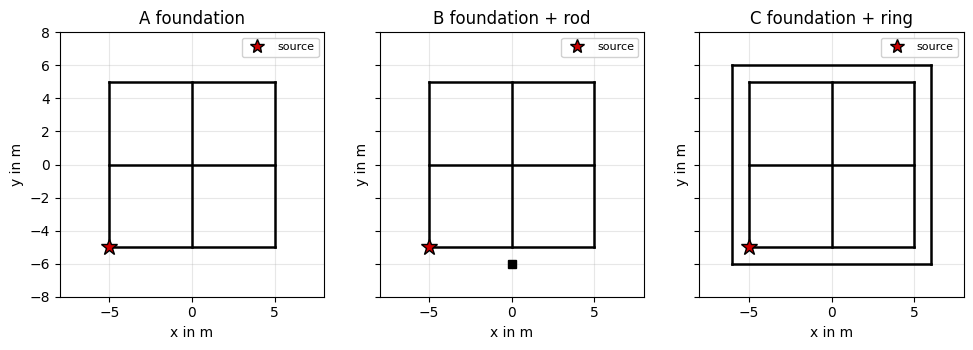

In [2]:
fig, axes = plt.subplots(1, 3, figsize=(10, 3.6), sharey=True)
titles = {"A": "A foundation", "B": "B foundation + rod", "C": "C foundation + ring"}
for ax, (key, extras) in zip(axes, VARIANTS.items(), strict=True):
    gf.plot_world(
        house(SOILS["S1"], extras=extras),
        ax=ax,
        extent=(-8.0, 8.0, -8.0, 8.0),
        show_conductors=False,
        title=titles[key],
    )
fig.tight_layout()

world = house(SOILS["S1"])
for e in world.electrodes:
    c = e.concrete_shell_coefficient_ohm_m
    print(
        f"{e.name:22s} {e.kind:8s} {e.total_length():4.1f} m, "
        f"r_b = {1000 * e.wire_radius:.0f} mm, C = {c:.2f} Ohm m"
    )
C_150 = gf.concrete_shell_coefficient(RHO_C, R_A, COVER)
print(f"C from the formula: {C_150:.2f} Ohm m")
print("checks of the world:", gf.diagnose(world, IMAGE))

In [3]:
assert len(world.electrodes) == 6
for e in world.electrodes:
    assert abs(e.concrete_shell_coefficient_ohm_m - C_150) < 1e-12
assert all(e.wire_radius == R_A + COVER for e in world.electrodes)

## Earthing resistance in homogeneous soil

The base case: the foundation earth electrode in earth-moist concrete in
100 Ω·m. Two neighbours help to read the number: the same bars bare in
the soil, and the foundation without its two cross-braces. Sverak's
formula of IEEE Std 80 (Eq. 57) is a plausibility check; it is an
empirical fit for bare substation grids from the total conductor length
$L_T$, the area $A$ and the depth $h$,

$$
R_g = \rho\left[\frac{1}{L_T} + \frac{1}{\sqrt{20A}}\left(1 +
\frac{1}{1 + h\sqrt{20/A}}\right)\right],
$$

so it is compared with the bare bars.

In [4]:
s1 = SOILS["S1"]
r_base = r_e(house(s1))
r_bare = r_e(house(s1, rho_c=None))
r_loop = r_e(house(s1, style="ring"))
r_sverak = ieee80.grid_resistance_sverak(
    100.0, total_conductor_length=6 * SIDE, area=SIDE**2, depth=DEPTH
)
print(f"foundation, concrete 150 Ohm m:         R_E = {r_base:.3f} Ohm")
print(f"the same bars bare in the soil:         R_E = {r_bare:.3f} Ohm")
print(f"without the cross-braces, in concrete:  R_E = {r_loop:.3f} Ohm")
print(
    f"IEEE Std 80 (Sverak), bare bars:        R_g = {r_sverak:.3f} Ohm "
    f"({r_sverak / r_bare - 1:+.0%} against the bare bars)"
)

foundation, concrete 150 Ohm m:         R_E = 5.010 Ohm
the same bars bare in the soil:         R_E = 4.688 Ohm
without the cross-braces, in concrete:  R_E = 5.726 Ohm
IEEE Std 80 (Sverak), bare bars:        R_g = 5.550 Ohm (+18% against the bare bars)


In [5]:
assert 4.5 < r_base < 5.5  # about rho / 20 m
assert r_bare < r_base < r_loop
assert abs(r_sverak / r_bare - 1.0) < 0.25  # an empirical formula

The house earth has about 5 Ω in 100 Ω·m soil, roughly $\rho$ / 20 m.
Earth-moist concrete adds 7 % to the bare bars. The cross-braces matter
more than one might expect: without them the loop alone has 14 % more,
because the braces add 50 % to the encased length and spread the current
over the area. Sverak's formula lies 18 % above the bare bars, within
what an empirical fit for much larger grids can promise.

## How much the concrete matters

The concrete resistivity $\rho_c$ is the least known input: it follows
the moisture of the foundation. The sweep below runs from wet concrete
(30 Ω·m) to dry concrete (10 000 Ω·m) in all three soils. The shell
resistance $C/L$ of the 60 m of encased bar is drawn for reference.

bars bare in the soil: {'S1': 4.69, 'S2': 6.83, 'S3': 7.22}


,S1,S2,S3,C/L
rho_c in Ohm m,,,,
30.0,4.22,5.09,7.08,0.19
50.0,4.36,5.22,7.22,0.32
100.0,4.68,5.54,7.57,0.64
150.0,5.01,5.86,7.90,0.95
300.0,5.98,6.82,8.89,1.91
1000.0,10.45,11.28,13.37,6.36
3000.0,23.18,24.01,26.11,19.08
5000.0,35.90,36.74,38.83,31.80
10000.0,67.71,68.54,70.64,63.61


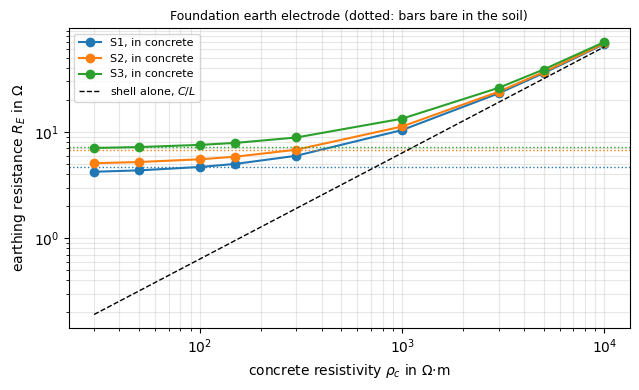

In [6]:
rho_c_values = np.array([30, 50, 100, 150, 300, 1000, 3000, 5000, 10000], dtype=float)
C_values = np.array(
    [gf.concrete_shell_coefficient(rc, R_A, COVER) for rc in rho_c_values]
)
shell = C_values / 60.0  # C / L over the 60 m of encased bar
sweep = {
    key: np.array([r_e(house(soil, rho_c=rc)) for rc in rho_c_values])
    for key, soil in SOILS.items()
}
bare = {key: r_e(house(soil, rho_c=None)) for key, soil in SOILS.items()}

fig, ax = plt.subplots(figsize=(6.5, 4.0))
for k, (key, values) in enumerate(sweep.items()):
    ax.loglog(rho_c_values, values, "o-", color=f"C{k}", label=f"{key}, in concrete")
    ax.axhline(bare[key], color=f"C{k}", ls=":", lw=1)
ax.loglog(rho_c_values, shell, "k--", lw=1, label="shell alone, $C/L$")
ax.set_xlabel(r"concrete resistivity $\rho_c$ in Ω·m")
ax.set_ylabel(r"earthing resistance $R_E$ in Ω")
ax.set_title("Foundation earth electrode (dotted: bars bare in the soil)", fontsize=9)
ax.grid(True, which="both", alpha=0.3)
ax.legend(fontsize=8)
fig.tight_layout()

print("bars bare in the soil:", {key: round(value, 2) for key, value in bare.items()})
table = pd.DataFrame(sweep, index=pd.Index(rho_c_values, name="rho_c in Ohm m"))
table["C/L"] = shell
table.round(2)

To separate the shell from the soil, a perfectly conducting shell
($\rho_c$ = 1 µΩ·m, $C \approx 0$) gives the resistance of the thick
wire of radius $r_b$ alone. The rise above it, divided by $C/L$, should
not fall below 1: the shell term is smallest when the current leaves
every metre of bar evenly, and the bonded bars choose the distribution
with the least total resistance. A dry shell forces that even
distribution, so the ratio should approach 1.

In [7]:
r_thick = r_e(house(s1, rho_c=1e-6))
ratio = (sweep["S1"] - r_thick) / shell
print(f"thick wire r_b alone: {r_thick:.3f} Ohm")
print(f"bars of r_a bare:     {bare['S1']:.3f} Ohm")
print("rise / (C/L):", np.round(ratio, 4))

thick wire r_b alone: 4.021 Ohm
bars of r_a bare:     4.688 Ohm
rise / (C/L): [1.0555 1.0512 1.0428 1.0369 1.026  1.0109 1.0041 1.0025 1.0013]


In [8]:
assert np.all(ratio > 1.0 - 1e-9) and np.all(ratio < 1.06)
assert np.all(np.diff(ratio) < 0) and ratio[-1] < 1.002  # dry: even current
# Concrete as resistive as the soil (100 Ohm m in S1) changes nearly nothing.
assert abs(sweep["S1"][rho_c_values == 100.0][0] / bare["S1"] - 1.0) < 2e-3
# Dry concrete dominates: the three soils end within 10 % of each other.
dry = [values[rho_c_values == 5000.0][0] for values in sweep.values()]
assert max(dry) / min(dry) < 1.10

What the sweep says:

- **Concrete as conductive as the soil changes nothing**; wetter concrete
  lowers $R_E$ a little, because the soil then sees bars eleven times
  thicker. In S2, whose top layer (300 Ω·m) is worse than earth-moist
  concrete, the concrete even improves the earth.
- **Dry concrete dominates.** From about $\rho_c \approx 10\,\rho$ on, the
  shell term $C/L$ outgrows the soil part, and at 5 000 Ω·m the earth
  has 36 … 39 Ω in all three soils: the soil hardly matters any more.
  Concrete that dries from earth-moist (150 Ω·m) to cycling humidity
  (1 000 Ω·m) already doubles the earthing resistance.
- The decomposition holds: the rise above the thick wire is 1.055 $C/L$
  for wet concrete and tends to $C/L$ for dry concrete, because a dry
  shell evens out the current over the bars.

## The soil model

A homogeneous soil is what a single measurement at a short probe spacing
suggests. The table compares the two-layer soils with the homogeneous
soils of their top and bottom layers.

In [9]:
rows = {}
for key in ("S2", "S3"):
    soil = SOILS[key]
    rows[key] = {
        "two layers": r_e(house(soil)),
        "homogeneous rho_1": r_e(house(gf.HomogeneousSoil(rho=soil.rho_1))),
        "homogeneous rho_2": r_e(house(gf.HomogeneousSoil(rho=soil.rho_2))),
    }
pd.DataFrame(rows).T.round(2)

,two layers,homogeneous rho_1,homogeneous rho_2
S2,5.86,13.07,2.18
S3,7.90,2.99,21.11


In [10]:
for row in rows.values():
    low, high = sorted((row["homogeneous rho_1"], row["homogeneous rho_2"]))
    assert low < row["two layers"] < high
assert rows["S2"]["homogeneous rho_1"] / rows["S2"]["two layers"] > 2.0
assert rows["S3"]["two layers"] / rows["S3"]["homogeneous rho_1"] > 2.0

Taking the top layer as homogeneous misjudges the earth by a factor of
2.2 … 2.6 either way: too high over a water-bearing layer (S2), too low
over gravel (S3), which is the unsafe side.

How deep does the house earth feel the soil, and when does a driven rod
pay off? The sweep below moves the interface of S2 (300 Ω·m over
30 Ω·m) from 1.5 m to 20 m for the three variants.

h_1 in m:             [ 1.5  2.   3.   4.   5.   8.  12.  20. ]
R_E of A in Ohm:      [ 5.11  5.86  6.99  7.85  8.53  9.86 10.81 11.67]
rod gain 1 - R_B/R_A: [0.37 0.39 0.4  0.37 0.31 0.08 0.07 0.06]


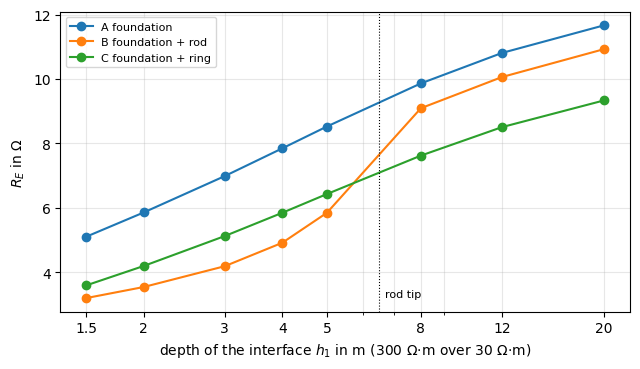

In [11]:
h_values = np.array([1.5, 2.0, 3.0, 4.0, 5.0, 8.0, 12.0, 20.0])
h_soils = [gf.TwoLayerSoil(rho_1=300.0, rho_2=30.0, h_1=h) for h in h_values]
h_sweep = {
    key: np.array([r_e(house(soil, extras=ex)) for soil in h_soils])
    for key, ex in VARIANTS.items()
}
fig, ax = plt.subplots(figsize=(6.5, 3.8))
for key, values in h_sweep.items():
    ax.semilogx(h_values, values, "o-", label=titles[key])
ax.axvline(6.5, color="k", lw=0.8, ls=":")
ax.text(6.7, 0.05, "rod tip", transform=ax.get_xaxis_transform(), fontsize=8)
ax.set_xticks(h_values, [f"{h:g}" for h in h_values])
ax.set_xlabel("depth of the interface $h_1$ in m (300 Ω·m over 30 Ω·m)")
ax.set_ylabel(r"$R_E$ in Ω")
ax.grid(True, which="both", alpha=0.3)
ax.legend(fontsize=8)
fig.tight_layout()
gain = 1.0 - h_sweep["B"] / h_sweep["A"]
print("h_1 in m:            ", h_values)
print("R_E of A in Ohm:     ", np.round(h_sweep["A"], 2))
print("rod gain 1 - R_B/R_A:", np.round(gain, 2))

In [12]:
assert np.all(np.diff(h_sweep["A"]) > 0)  # a deeper good layer helps less
assert gain[h_values == 2.0][0] > 0.35 and gain[h_values == 12.0][0] < 0.10

- **The foundation feels the soil deep down.** Even with the interface
  20 m deep, twice the size of the house, the conductive layer still
  lowers its resistance by 11 % against homogeneous 300 Ω·m (11.67 Ω
  against 13.07 Ω). A sounding should reach a few times the size of the
  house.
- **The rod pays off while it reaches the conductive layer** (interface
  above its tip at 6.5 m): it cuts the earthing resistance by 31 … 40 %.
  Once the good layer lies below the tip, the gain drops to the 6 … 8 %
  of a rod in the resistive layer.

## A rod or a ring earth electrode outside the foundation

The earthing resistance of the three variants in the three soils, with
earth-moist concrete (150 Ω·m) and with dry concrete (5 000 Ω·m):

In [13]:
variants_re = {
    (state, key): {
        f"{v}": r_e(house(soil, rho_c=rho_c, extras=ex)) for v, ex in VARIANTS.items()
    }
    for state, rho_c in (("moist", RHO_C), ("dry", 5000.0))
    for key, soil in SOILS.items()
}
re_table = pd.DataFrame(variants_re)  # rows: variants; columns: concrete, soil
re_table.round(2)

moist                dry              
     S1    S2    S3     S1     S2     S3
A  5.01  5.86  7.90  35.90  36.74  38.83
B  4.60  3.54  7.75  13.03   6.01  19.93
C  3.72  4.20  6.48   4.41   6.67   6.67

In [14]:
moist, dry = re_table["moist"], re_table["dry"]
assert np.all(re_table.loc["B"] < re_table.loc["A"])
assert np.all(re_table.loc["C"] < re_table.loc["A"])
# The rod reaches the water-bearing layer in S2, and ends in gravel in S3.
assert moist.loc["B", "S2"] / moist.loc["A", "S2"] < 0.65
assert moist.loc["B", "S3"] / moist.loc["A", "S3"] > 0.95
# Dry concrete: the foundation alone rises several times, the ring holds.
assert np.all(dry.loc["A"] > 4.0 * moist.loc["A"])
assert np.all(dry.loc["C"] < 1.7 * moist.loc["C"])
assert np.all(dry.loc["C"] < 0.2 * dry.loc["A"])

- **The rod** helps where it reaches better soil: −40 % in S2, where it
  reaches the water-bearing layer, but −8 % in S1 and −2 % in S3, where
  it ends in gravel.
- **The ring** lowers $R_E$ by 18 … 28 % with moist concrete. Its real
  value shows with dry concrete: the foundation alone rises to
  36 … 39 Ω, while the bare ring in the soil keeps the earth at
  4.4 … 6.7 Ω. Where the foundation is insulated or may dry out, the
  ring is the earth.
- With dry concrete the rod, too, takes over most of the current and
  lowers $R_E$ by 49 … 84 %, because the foundation then leaks so
  little.

## Potential profile, touch and step voltage

When the earth of the house rises to the earth potential rise $U_E$,
every part bonded to it — the main earthing terminal, the pipes, an
outdoor tap, the meter cabinet — rises with it, while the soil outside
lies lower. A person standing on the ground 1 m from a touched part
bridges the **touch voltage** $U_T = U_E - \varphi(\text{feet})$, and a
person walking bridges the **step voltage** between two points 1 m
apart (see [T08](../tutorials/T08_touch_and_step_assessment.ipynb)).

The field is linear in the current. The ratios $U_T/U_E$ and $U_S/U_E$
therefore depend only on the geometry and the soil, not on the current
nor on what raises the potential: a current that flows through the house
earth ($U_E = R_E I_E$), or a potential transferred to the house via the
PEN conductor from a substation in fault. The feet stand 1 m from the
foundation bar, about 0.8 m in front of the façade; the inside of the
footprint is not sampled, because there stands the house.

The image engine warns that its uniform current is only impedance-grade
next to a bonded cluster of wires, so the field is computed with `mom`
(the engines section below quantifies the difference).

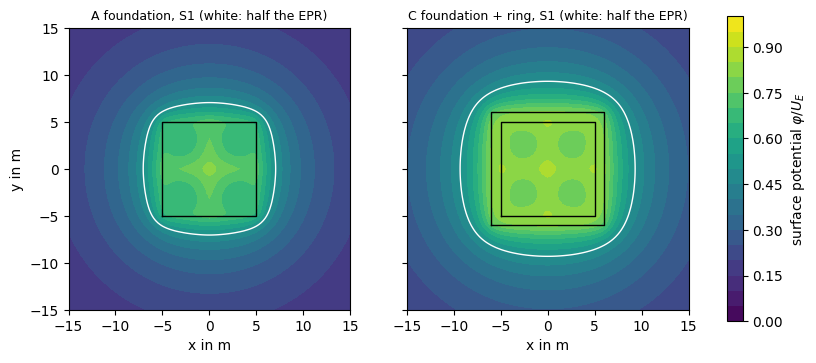

In [15]:
def field(soil, rho_c=RHO_C, extras=()):
    # mom solution and its earth potential rise per ampere.
    world = house(soil, rho_c=rho_c, extras=extras)
    result = MOM.solve(world)
    return world, result, result.input_impedance()[0].real


def surface(result, x, y):
    # Surface potential at the points (x, y), in V per A.
    pts = np.column_stack([np.ravel(x), np.ravel(y), np.zeros(np.size(x))])
    return result.potential(pts).real.reshape(np.shape(x))


x = np.linspace(-15.0, 15.0, 121)
X, Y = np.meshgrid(x, x)
fig, axes = plt.subplots(1, 2, figsize=(10, 4.4), sharey=True)
for ax, key in zip(axes, ("A", "C"), strict=True):
    world, result, u_e = field(SOILS["S1"], extras=VARIANTS[key])
    phi = surface(result, X, Y) / u_e
    cs = ax.contourf(X, Y, phi, levels=np.linspace(0.0, 1.0, 21), cmap="viridis")
    ax.contour(X, Y, phi, levels=[0.5], colors="w", linewidths=1)
    for h in [5.0] + ([6.0] if key == "C" else []):  # foundation, ring
        ax.plot([-h, h, h, -h, -h], [-h, -h, h, h, -h], "k-", lw=1)
    ax.set_aspect("equal")
    ax.set_title(f"{titles[key]}, S1 (white: half the EPR)", fontsize=9)
    ax.set_xlabel("x in m")
axes[0].set_ylabel("y in m")
cbar = fig.colorbar(cs, ax=axes, label=r"surface potential $\varphi / U_E$", shrink=0.9)

A foundation, moist concrete           phi/U_E at the centre 0.82, at x = 6 m 0.60
B foundation + rod, moist concrete     phi/U_E at the centre 0.83, at x = 6 m 0.62
C foundation + ring, moist concrete    phi/U_E at the centre 0.87, at x = 6 m 0.81
A foundation, dry concrete             phi/U_E at the centre 0.13, at x = 6 m 0.08
C foundation + ring, dry concrete      phi/U_E at the centre 0.56, at x = 6 m 0.70


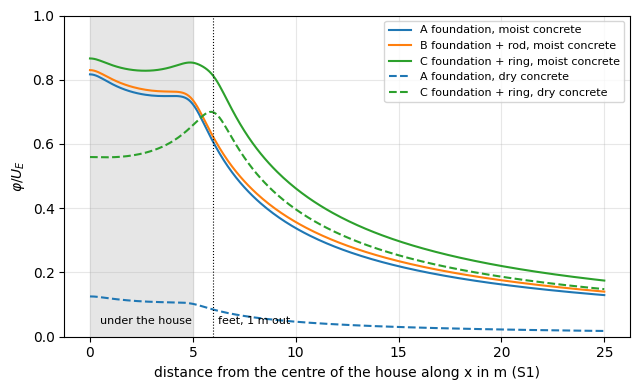

In [16]:
s = np.linspace(0.0, 25.0, 251)  # m from the centre of the house along +x
fig, ax = plt.subplots(figsize=(6.5, 4.0))
profiles = [("A", RHO_C), ("B", RHO_C), ("C", RHO_C), ("A", 5000.0), ("C", 5000.0)]
for key, rho_c in profiles:
    ls = "-" if rho_c == RHO_C else "--"
    _, result, u_e = field(SOILS["S1"], rho_c=rho_c, extras=VARIANTS[key])
    color = {"A": "C0", "B": "C1", "C": "C2"}[key]
    label = f"{titles[key]}, " + ("moist" if rho_c == RHO_C else "dry") + " concrete"
    profile = surface(result, s, 0 * s) / u_e
    ax.plot(s, profile, ls, color=color, label=label)
    print(
        f"{label:38s} phi/U_E at the centre {profile[0]:.2f}, at x = 6 m {profile[60]:.2f}"
    )
ax.axvspan(0.0, 5.0, color="0.9")
ax.text(0.5, 0.04, "under the house", fontsize=8)
ax.axvline(6.0, color="k", lw=0.8, ls=":")
ax.text(6.2, 0.04, "feet, 1 m out", fontsize=8)
ax.set_xlabel("distance from the centre of the house along x in m (S1)")
ax.set_ylabel(r"$\varphi / U_E$")
ax.set_ylim(0.0, 1.0)
ax.grid(alpha=0.3)
ax.legend(fontsize=8)
fig.tight_layout()

Under the house the ground stays at about 0.8 $U_E$ with moist concrete:
the foundation grades the potential of the floor, which is why it serves
as protective bonding as well as an earth. Outside, the potential falls
steeply: at the feet 1 m out, 40 % of the earth potential rise is gone in
front of the middle of a wall and about half at a corner (the map). The
ring 1 m outside lifts the potential exactly where people stand (0.81
instead of 0.60 $U_E$ in front of the wall). With dry concrete the shell
takes up most of the voltage, and the soil around the house hardly rises
at all (0.08 $U_E$ at the feet): the bonded parts are at $U_E$ while the
ground is close to remote earth.

The table collects, for every soil and variant (moist concrete) and for
dry concrete in S1:

- $R_E$ from `mom`;
- the largest touch voltage on the curve 1 m from the bars
  (`gf.touch_voltage_envelope`, 72 directions), as a fraction of $U_E$
  and per ampere of earth current;
- the largest step voltage, as a fraction of $U_E$, from the foundation
  line outwards along the axis and the diagonal of the house.

In [17]:
def assess(soil, rho_c=RHO_C, extras=()):
    world, result, u_e = field(soil, rho_c=rho_c, extras=extras)
    _, u_t = gf.touch_voltage_envelope(result, world, electrode=FOUNDATION, n_angles=72)
    u_s = 0.0
    for start, d in ((5.0, (1.0, 0.0)), (5.0 * math.sqrt(2.0), (1.0, 1.0))):
        d = np.array(d) / np.hypot(*d)
        r = np.arange(start, 30.0, 0.05)
        phi = surface(result, r * d[0], r * d[1])
        phi_1m = surface(result, (r + 1.0) * d[0], (r + 1.0) * d[1])
        u_s = max(u_s, np.max(phi - phi_1m))
    u_t_max = np.max(np.abs(u_t))
    return {
        "R_E": u_e,
        "U_T/U_E": u_t_max / u_e,
        "U_T/I_E": u_t_max,  # V per A of earth current
        "U_S/U_E": u_s / u_e,
    }


cases = {(k, v): (SOILS[k], RHO_C, ex) for k in SOILS for v, ex in VARIANTS.items()}
cases.update({("S1 dry", v): (SOILS["S1"], 5000.0, ex) for v, ex in VARIANTS.items()})
safety = pd.DataFrame({case: assess(*args) for case, args in cases.items()}).T
safety.index.names = ["soil", "variant"]
safety.round(3)

R_E  U_T/U_E  U_T/I_E  U_S/U_E
soil   variant                                   
S1     A         4.964    0.513    2.544    0.127
       B         4.549    0.501    2.279    0.125
       C         3.694    0.241    0.890    0.141
S2     A         5.730    0.722    4.139    0.221
       B         3.479    0.693    2.409    0.210
       C         4.129    0.432    1.783    0.214
S3     A         7.868    0.293    2.304    0.068
       B         7.710    0.289    2.228    0.068
       C         6.452    0.101    0.655    0.075
S1 dry A        35.870    0.934   33.508    0.018
       B        12.899    0.879   11.335    0.023
       C         4.373    0.313    1.367    0.138

In [18]:
ratio_t = safety["U_T/U_E"]
by_variant = {v: ratio_t.xs(v, level="variant") for v in VARIANTS}
assert np.all(by_variant["C"] < 0.65 * by_variant["A"])
assert ratio_t[("S1 dry", "A")] > 0.9  # dry concrete: almost the full EPR
assert ratio_t[("S2", "A")] > ratio_t[("S1", "A")] > ratio_t[("S3", "A")]
assert np.all(safety["U_S/U_E"] < safety["U_T/U_E"])
# The rod lowers R_E, hardly the ratio; per ampere it still helps.
assert abs(ratio_t[("S1", "B")] / ratio_t[("S1", "A")] - 1.0) < 0.05
assert safety.loc[("S2", "B"), "U_T/I_E"] < 0.7 * safety.loc[("S2", "A"), "U_T/I_E"]
# One point of the scan with the library's own step-voltage helper:
world, result, u_e = field(SOILS["S1"])
u_s_helper = gf.step_voltage(
    result, position=(5.0, 0.0, 0.0), direction=(1.0, 0.0, 0.0)
)
u_s_scan = surface(result, 5.0, 0.0) - surface(result, 6.0, 0.0)
assert abs(u_s_helper - u_s_scan) < 1e-9

How to read the table:

- **Touch voltage.** With the foundation alone, about half the earth
  potential rise appears as touch voltage in S1; in S2, whose resistive
  top layer lets the current dive to the conductive layer, almost three
  quarters; in S3, whose conductive top layer spreads it sideways, under
  a third. The ring lowers the ratio to a third … three fifths of its
  value without it. The rod leaves the ratio almost unchanged: it lowers
  $R_E$, so it helps where a current sets the earth potential rise (the
  column per ampere: −42 % in S2), not where a potential is transferred.
- **Dry concrete** raises the ratio to 0.93: the touch voltage is then
  practically the full earth potential rise, and per ampere 13 times that
  of the moist foundation. The ring brings it back to 0.31.
- **Step voltages** stay below the touch voltages, with their largest
  values just outside the foundation bars (or outside the ring).

## What the touch voltages allow

EN 50522 limits the touch voltage $U_{Tp}$ by the fault duration $t_f$
(Table B.4: 225 V at 0.5 s; 80 V beyond 10 s and for an earth fault that
is not cleared). It applies to earth faults in high-voltage
installations; a house in a TN network meets them as a potential
transferred via the PEN conductor. The low-voltage installation itself
has its own rules (IEC 60364-4-41). The ratio $U_T/U_E$ turns $U_{Tp}$
into the largest earth potential rise the house can carry without extra
measures, $U_{E,\max} = U_{Tp} / (U_T/U_E)$:

In [19]:
u_tp = {
    "0.5 s": gf.permissible_touch_voltage_en50522(0.5),
    "not cleared": gf.permissible_touch_voltage_en50522(math.inf),
}
allowed = pd.DataFrame({f"U_E,max ({k}) in V": v / ratio_t for k, v in u_tp.items()})
print({k: f"U_Tp = {v:.0f} V" for k, v in u_tp.items()})
allowed.round(0)

{'0.5 s': 'U_Tp = 225 V', 'not cleared': 'U_Tp = 80 V'}


U_E,max (0.5 s) in V  U_E,max (not cleared) in V
soil   variant                                                  
S1     A                       439.0                       156.0
       B                       449.0                       160.0
       C                       933.0                       332.0
S2     A                       312.0                       111.0
       B                       325.0                       116.0
       C                       521.0                       185.0
S3     A                       768.0                       273.0
       B                       779.0                       277.0
       C                      2217.0                       788.0
S1 dry A                       241.0                        86.0
       B                       256.0                        91.0
       C                       720.0                       256.0

In [20]:
assert u_tp["0.5 s"] == 225.0 and u_tp["not cleared"] == 80.0
assert np.all(allowed.iloc[:, 0] > u_tp["0.5 s"])  # every case carries more than U_Tp

A foundation earth electrode in moist concrete lets the house carry
roughly twice $U_{Tp}$ as earth potential rise (S1: 439 V for a fault
cleared in 0.5 s, 156 V for one that is not cleared); the ring outside
doubles that again. Over the water-bearing layer of S2 and with dry
concrete the margin shrinks towards $U_{Tp}$ itself. In a real TN
network the neighbouring house earths and the substation raise the soil
around the house as well, which lowers the touch voltage further; for
the touch voltage this single house is the pessimistic end (see the case
study [E01](E01_secondary_substation_and_lv_network.ipynb) of a secondary substation with its low-voltage network).

## The engines compared

### `image` against `mom` on the house

The image engine carries one uniform leakage current per straight bar
and integrates the line source exactly. `mom` gives every 0.5 m segment
its own current, so the current can crowd towards the corners and ends
of the bars, but evaluates each segment as a point source. The cell
compares $R_E$ and the touch-voltage ratio of variants A and C, moist
concrete, in the three soils, and records the warning of the image
engine.

In [21]:
rows = {}
with warnings.catch_warnings(record=True) as caught:
    warnings.simplefilter("always")
    for key, soil in SOILS.items():
        for v in ("A", "C"):
            world = house(soil, extras=VARIANTS[v])
            res = {"image": IMAGE.solve(world), "mom": MOM.solve(world)}
            z = {n: r.input_impedance()[0].real for n, r in res.items()}
            u_t = {}
            for n, r in res.items():
                _, u = gf.touch_voltage_envelope(
                    r, world, electrode=FOUNDATION, n_angles=72
                )
                u_t[n] = np.abs(u).max() / z[n]
            rows[(key, v)] = {
                "R_E image": z["image"],
                "R_E mom": z["mom"],
                "image/mom - 1": z["image"] / z["mom"] - 1.0,
                "U_T/U_E image/mom - 1": u_t["image"] / u_t["mom"] - 1.0,
            }
engines = pd.DataFrame(rows).T
caveat = [w for w in caught if issubclass(w.category, gf.UniformCurrentFieldWarning)]
print(f"{len(caveat)} x UniformCurrentFieldWarning, the first one:")
print(str(caveat[0].message)[:240], "...")
engines.round(4)

6 x UniformCurrentFieldWarning, the first one:
touch_voltage_envelope: uniform-current backend 'image' within 5 m of a grid, mesh, star, strip, open polyline or bonded multi-electrode cluster: the surface potential is impedance-grade (against 'mom': 20 m grid corner touch 1 m outside +6 ...


R_E image  R_E mom  image/mom - 1  U_T/U_E image/mom - 1
S1 A     5.0103   4.9638         0.0094                 0.0174
   C     3.7195   3.6939         0.0069                 0.0939
S2 A     5.8586   5.7303         0.0224                 0.0123
   C     4.1977   4.1295         0.0165                 0.0525
S3 A     7.9036   7.8678         0.0045                 0.0200
   C     6.4803   6.4520         0.0044                 0.1571

In [22]:
assert len(caveat) >= 1
assert np.all((engines["image/mom - 1"] > 0) & (engines["image/mom - 1"] < 0.025))
touch = engines["U_T/U_E image/mom - 1"]
assert np.all(np.abs(touch.xs("A", level=1)) < 0.03)  # foundation alone
assert np.all((touch.xs("C", level=1) > 0.03) & (touch.xs("C", level=1) < 0.2))

- **The earthing resistance** of the image engine lies 0.4 … 2.2 % above
  `mom`. For impedances the uniform current per bar is a good
  approximation.
- **The touch voltage of the foundation alone** agrees within about 2 %.
- **The touch voltage over the ring (variant C)** is 5 … 16 % higher with
  the image engine. The feet stand right above the ring, where the
  surface potential depends on how the current is distributed along each
  side; in reality it crowds towards the corners, the image engine keeps
  it uniform per side. The error is on the safe side here, but it is the
  reason for the warning: for the field next to bonded clusters, grids,
  stars and strip ends, use `mom` (tutorial T08).

### The segment length

The image engine's line kernel integrates every straight bar exactly, so
a square foundation gives the same resistance at every segment length.
`mom` converges with the segment length:

In [23]:
world = house(SOILS["S1"])
ladder = [2.0, 1.0, 0.5, 0.3]
conv = {
    name: gf.convergence_study(world, eng, segment_lengths=ladder)["Z_re"].to_numpy()
    for name, eng in (("image", IMAGE), ("mom", MOM))
}
pd.DataFrame(conv, index=pd.Index(ladder, name="segment length in m")).round(5)

,image,mom
segment length in m,,
2.0,5.01033,4.96177
1.0,5.01033,4.96205
0.5,5.01033,4.96385
0.3,5.01033,4.96475


In [24]:
assert np.ptp(conv["image"]) < 1e-6 * conv["image"][-1]
assert np.ptp(conv["mom"]) < 1e-3 * conv["mom"][-1]

### `fem` on a ring analogue (axisymmetric model)

`fem` meshes the soil and treats each electrode as the solid body it is:
a rod as a cylinder, a ring as a torus, the concrete shell as a surface
conductance $1/(2\pi r_b C)$ on the surface of radius $r_b$. Its
axisymmetric model solves rods on one vertical axis and rings around it
to about $10^{-4}$, in a fraction of a second. A square foundation is not
axisymmetric, so we take a ring analogue: a circular ring with the same
40 m of encased bar as the foundation loop without cross-braces
(radius $40\,\mathrm{m}/2\pi$ = 6.37 m, 0.8 m deep) in earth-moist
concrete, in the three soils. The shell rise is measured against the
same ring with a perfectly conducting shell ($C = 0$).

In [25]:
R_RING = 4.0 * SIDE / (2.0 * math.pi)
C_LOOP = C_150 / (2.0 * math.pi * R_RING)  # the shell term C / L of the ring


def ring_analogue(soil, shell=True):
    # Circular ring of radius r_b = 55 mm; shell=False: C = 0.
    world = gf.create_world(soil=soil, name="E02 ring analogue")
    gf.create_electrode(
        world,
        "ring",
        name="ring",
        center=(0.0, 0.0, DEPTH),
        radius=R_RING,
        wire_radius=R_A + COVER,
        concrete_shell_coefficient_ohm_m=C_150 if shell else 0.0,
    )
    gf.create_source(world, attached_to="ring", magnitude=1.0)
    return world


FEM = gf.create_engine(backend="fem", segment_length=0.5)  # axisymmetric here
ENGINES = {"image": IMAGE, "mom": MOM, "fem": FEM}
rows, timing = {}, {}
with warnings.catch_warnings():
    # fem is experimental and says so once per process.
    warnings.simplefilter("ignore", gf.ExperimentalBackendWarning)
    for key, soil in SOILS.items():
        world, z, ratio = ring_analogue(soil), {}, {}
        for name, eng in ENGINES.items():
            t0 = time.perf_counter()
            res = eng.solve(world)
            timing[name] = time.perf_counter() - t0
            z[name] = res.input_impedance()[0].real
            ratio[name] = abs(gf.touch_voltage(res, world, electrode="ring")) / z[name]
        fem_thick = r_e(ring_analogue(soil, shell=False), FEM)
        rows[key] = {
            "R_E fem": z["fem"],
            "image/fem-1": z["image"] / z["fem"] - 1.0,
            "mom/fem-1": z["mom"] / z["fem"] - 1.0,
            "fem rise/(C/L)": (z["fem"] - fem_thick) / C_LOOP,
            "U_T image/fem-1": ratio["image"] / ratio["fem"] - 1.0,
        }
ring_table = pd.DataFrame(rows).T
ring_table.round(5)

,R_E fem,image/fem-1,mom/fem-1,fem rise/(C/L),U_T image/fem-1
S1,5.52242,-0.00027,-0.00841,1.00101,-0.00028
S2,7.27947,-0.00032,-0.01900,1.00206,-0.00016
S3,8.05786,-0.00021,-0.00294,1.00133,-0.00053


In [26]:
assert np.all(np.abs(ring_table["image/fem-1"]) < 1e-3)
assert np.all((ring_table["mom/fem-1"] < 0) & (ring_table["mom/fem-1"] > -0.03))
rise = ring_table["fem rise/(C/L)"]
assert np.all((rise >= 1.0) & (rise < 1.01))
assert np.all(np.abs(ring_table["U_T image/fem-1"]) < 2e-3)

Three independent methods, one ring:

- **`image` agrees with `fem` to a few $10^{-4}$**, in resistance and in
  touch voltage. On a ring the uniform current is exact by symmetry, so
  the only difference left is the image engine's polygon of 0.5 m chords,
  which lies slightly inside the circle.
- **`mom` lies 0.3 … 1.9 % below.** Its point kernel represents each
  segment's current by a point source at the segment's midpoint, which
  reads the resistance low; this deficit does not vanish as the segments
  get shorter (tutorial T09).
- **The shell model is consistent.** The image engine adds exactly
  $C/L$; `fem` adds 0.1 … 0.2 % more, because on the solid torus the
  current is not spread evenly around the wire's circumference, and an
  uneven current loses more in the shell.

### `fem` on the real foundation (three-dimensional model)

Every other world — the square loop, the braces, the rod beside the
foundation — needs the three-dimensional model of `fem`. It replaces each
wire by a line source smoothed over a disc of radius `source_radius`,
meshes the soil with tetrahedra and corrects for the wire radius
analytically. It needs the optional `fem3d` extra and is expensive: the
foundation loop without cross-braces (40 m of bar, S1, moist concrete),
with a 0.1 m source radius and the mesh growth 0.6, has 1.04 million
nodes on its finer mesh level. On the machine that executed this
notebook it took one to three minutes, depending on what else was
running, and up to 3.5 GB of memory. The cell below runs it only on
request and otherwise uses the value of that run.

In [27]:
RUN_FEM_3D = False  # 1 to 3 minutes, up to 3.5 GB of memory; needs the fem3d extra
FEM_3D_LOOP = 5.71518  # Ohm, recorded with RUN_FEM_3D = True (error estimate 3.5e-3)

loop = house(SOILS["S1"], style="ring")
if RUN_FEM_3D:
    options = {"fem": {"model": "3d", "source_radius": 0.1, "growth": 0.6}}
    engine = gf.create_engine(backend="fem", segment_length=0.5, options=options)
    fem3d = engine.solve(loop)
    z_fem3d = fem3d.input_impedance()[0].real
    print(f"error estimate {fem3d.metadata['fem_error_estimate']:.1e}")
else:
    z_fem3d = FEM_3D_LOOP
z_loop = {"image": r_e(loop), "mom": r_e(loop, MOM)}
print(f"fem 3-D: {z_fem3d:.4f} Ohm")
for name, z in z_loop.items():
    print(f"{name:5s}: {z:.4f} Ohm, {z / z_fem3d - 1:+.2%} against fem 3-D")

fem 3-D: 5.7152 Ohm
image: 5.7255 Ohm, +0.18% against fem 3-D
mom  : 5.6831 Ohm, -0.56% against fem 3-D


In [28]:
assert 0.0 < z_loop["image"] / z_fem3d - 1.0 < 0.01
assert -0.01 < z_loop["mom"] / z_fem3d - 1.0 < 0.0

On the square loop the picture of the ring repeats with one change: the
current now crowds towards the corners, which the uniform current per
side cannot follow, so `image` lies a little above `fem` (+0.18 %,
within the 3.5e-3 error estimate of the 3-D model), and `mom` below it by
its point kernel's deficit (−0.56 %). For the mesh foundation with braces
(1.5 million nodes) the [`fem` engine page](../explanation/engines/fem.md)
reports the same order: the image engine lies +0.14 / +0.03 % above the
3-D model with the braces encased in concrete of 1 000 / 5 000 Ω·m.

### What each engine costs here

Times of one solve on the machine that executed this notebook:

In [29]:
world = house(SOILS["S2"], extras=(RING,))
for name, eng in (("image_2layer", IMAGE), ("mom", MOM)):
    t0 = time.perf_counter()
    eng.solve(world)
    print(f"{name:13s} house C in S2:      {1000 * (time.perf_counter() - t0):7.1f} ms")
print(f"fem, axisymmetric, ring in S3:    {1000 * timing['fem']:7.1f} ms")
print("fem, 3-D, foundation loop in S1:  1 to 3 min, up to 3.5 GB (recorded above)")

image_2layer  house C in S2:         69.6 ms
mom           house C in S2:         40.5 ms
fem, axisymmetric, ring in S3:      219.7 ms
fem, 3-D, foundation loop in S1:  1 to 3 min, up to 3.5 GB (recorded above)


| Engine | Use it here for | $R_E$ for this house | Cost |
|---|---|---|---|
| `image` / `image_2layer` | earthing resistance, sweeps | +0.2 % against `fem` (loop) | tens of ms |
| `mom` | potential, touch and step voltage | −0.3 … −1.9 % against `fem` | tens of ms |
| `fem`, axisymmetric | reference for rings and rods on one axis | about $10^{-4}$ | under a second |
| `fem`, 3-D | reference for the real foundation | about $2\cdot10^{-3}$ | minutes, GB, `fem3d` extra |

The image engine lies 0.4 … 2.2 % above `mom` on the house and
overestimates the touch voltage over the ring by up to 16 % (see above);
that is why the field near the house comes from `mom`.

The pair `image` and `mom` brackets the solid-conductor value of `fem`
from above and below: the uniform current per wire overestimates the
resistance, the point kernel underestimates it. For an engineering
answer both are good to about 2 %, far below the uncertainty of the
concrete and the soil.

## What this means in practice

- A foundation earth electrode of a 10 m × 10 m house has about
  $\rho$ / 20 m in homogeneous soil (5.0 Ω in 100 Ω·m) as long as the
  concrete is moist.
- **The concrete** is neutral while it is about as conductive as the
  soil; dry concrete multiplies the earthing resistance (about 36 Ω at
  5 000 Ω·m) and makes the soil irrelevant.
- **The soil model** matters as much: the homogeneous soil of the top
  layer misjudges the earth by a factor of 2.2 … 2.6 either way, and the
  foundation still feels a layer 20 m down. Use a sounding that reaches a
  few times the size of the house.
- **A driven rod** pays off when it reaches a better layer (−40 % in S2);
  it lowers $R_E$ but not the touch voltage as a fraction of the earth
  potential rise.
- **A ring earth electrode 1 m outside** lowers $R_E$, cuts the touch
  voltage around the house by 40 … 67 % and keeps the earth working when
  the foundation dries out or is insulated.
- **Engines:** `image` for resistances and sweeps, `mom` for the field
  next to the house, `fem` to confirm a result once; they agree within
  about 2 %.

## Limits of this example

- **One house alone.** In a TN network the house is bonded through the
  PEN to the substation and to every other house; the global earthing
  system lowers both the earthing impedance seen at the house and the
  touch voltages around it (case study [E01](E01_secondary_substation_and_lv_network.ipynb)).
- **The concrete model** is a cylindrical shell of uniform resistivity
  around each bar. The real strip foundation is a block of concrete
  several times wider than the shell; DIN 18014 bonds the bar to the
  reinforcement at least every 2 m, which enlarges the electrode; and
  the moisture varies over the foundation and the year.
  Where bars meet, their shells overlap; the
  [concrete-shells page](../explanation/concrete-shells.md) estimates
  that this changes the house mesh by about 1 % or less.
- **The soil** is horizontally layered and uniform in each layer: no
  backfill around the foundation, no frost, no seasonal moisture profile.
- **Touch voltages** are prospective: no body, shoe or surface-layer
  resistance (EN 50522, Annex B, and
  `gf.permissible_prospective_touch_voltage_en50522` add them). The feet
  stand 1 m from the bars; touched parts farther out (a bonded fence, a
  garden tap on a pipe) carry the house potential to places where the
  soil lies lower and need their own assessment with
  `gf.touch_voltage_at_part`.
- **Frequency:** 50 Hz, no inductive conductor in the model; harmonics
  and lightning currents are outside its scope.
- **The 3-D `fem` reference** was run once for the loop without braces
  in S1; the other worlds rest on the agreement of `image` and `mom` and
  on the axisymmetric ring analogue.